Public-contract revision 2026-10-29

V1 required a particular finite IPG histogram despite the ill-posed size distribution. V2 preserves the original all-500-point noise discrepancy <=1.01, calibrated background and nonnegative histogram. Raw-only independently implemented column-scaled NNLS achieves chi-square .6924073; zero/reversed distributions fail. No actual truth exists. The earlier reference-comparison tables are historical v1 diagnostics, not current acceptance criteria. Current standalone Judge metrics are authoritative.

# From complete SAXS observations to a particle-radius density

This active review uses the existing author `OneDist1pctLarge`500-point curve. Its experimental versus synthetic origin is **unverified**; no specific material, wavelength or independent true distribution is invented. The latent object is a nonnegative **contrast-weighted volume density** Z(r) and flat nuisance background B. This parameter-space inverse differs from a spatial particle image or a summary Guinier radius.

The independent original source result is labeled **upstream**. Every **fresh** result below is computed using this task's local numerical modules, including the complete benchmark path and all ablations. No generating truth is available.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json,platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
if not (ROOT/'src').exists():ROOT=ROOT/'staging/tasks/saxs_contrast_weighted_particle_size_density'
assert (ROOT/'src').is_dir()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,radius_grid,bin_widths
from src.physics_model import sphere_amplitude,build_kernel,forward
from src.solvers import reconstruct
from src.main import run
from src.visualization import density_metrics,size_integrals
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.titlelocation':'left'})
q,I,error=load_observations(ROOT/'data/raw_data.npz')
up=np.load(ROOT/'notebooks/reference_outputs/upstream_standard.npz',allow_pickle=False)
print(platform.python_version(), 'NumPy',np.__version__,'SciPy',scipy.__version__)
print('Complete observation count',len(q),'q endpoints',q[[0,-1]])

3.11.11 NumPy 2.4.6 SciPy 1.17.1
Complete observation count 500 q endpoints [9.99999975e-05 1.00000000e+00]


## 1. Observations and the nuisance background

All500 original intensities and uncertainties are retained, spanning four decades in q. The high-q plateau constrains an additive background, while particle scattering dominates at low q. The supplied uncertainties are preserved exactly; their instrument-specific derivation was not supplied. The highlighted high-q observations support the source background estimator, but **all** observations also enter the subsequent inverse.

All500 supplied intensity weights equal0.03 times the same public observed intensity to within6.17e-16 relative floating-point roundtrip error. They are redundant public-data weights, not a clean-truth proxy or independently calibrated stochastic standard deviation. The discrepancy target weightedcost/N<=1 is the selected algorithm stopping convention; without verified stochastic noise it is not a calibrated chi-square goodness-of-fit test or p-value. Added-noise experiments are nominal-weight sensitivity experiments.

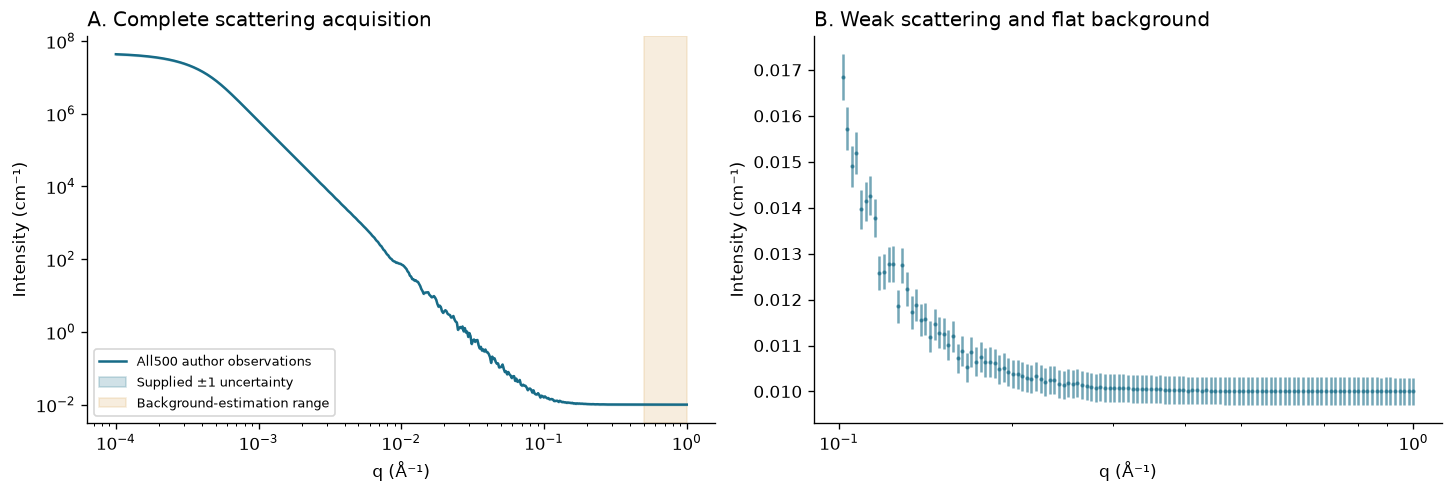

In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
ax[0].loglog(q,I,color='#176b87',label='All500 author observations');ax[0].fill_between(q,np.maximum(I-error,1e-9),I+error,color='#176b87',alpha=.2,label='Supplied ±1 uncertainty')
ax[0].axvspan(.5,1,color='#dba85b',alpha=.2,label='Background-estimation range');ax[0].legend(fontsize=8)
ax[0].set(xlabel='q (Å⁻¹)',ylabel='Intensity (cm⁻¹)',title='A. Complete scattering acquisition')
tail=q>=.1;ax[1].errorbar(q[tail],I[tail],yerr=error[tail],fmt='.',ms=3,color='#176b87',alpha=.6)
ax[1].set(xscale='log',xlabel='q (Å⁻¹)',ylabel='Intensity (cm⁻¹)',title='B. Weak scattering and flat background');plt.show()

## 2. Physics, units and the inverse operator

For a uniform sphere, $V(r)=4\pi r^3/3$ and $F(x)=3(\sin x-x\cos x)/x^3$, with $F(0)=1$. The pinhole dilute-limit observation model is

$$
I_i=B+\sum_j10^{-4}V(r_j)F(q_i r_j)^2Z_jw_j+\epsilon_i.
$$

Here q is in Å⁻¹, r and bin widths w in Å, I and B in cm⁻¹. Z is volume density multiplied by squared contrast expressed in10²⁰cm⁻⁴. The factor10⁻⁴ is10²⁰×10⁻²⁴, converting cubic angstroms to cubic centimeters. Setting contrast to one is this observable reparametrization; it is **not** evidence that the specimen's contrast is known. The operator integrates radius populations and loses high-frequency details. Nonnegative bin masses x=Zw are estimated by explicit preconditioned gradients with positivity-limited exact quadratic line searches. Discrepancy stopping requires standardized residual energy/500≤1.

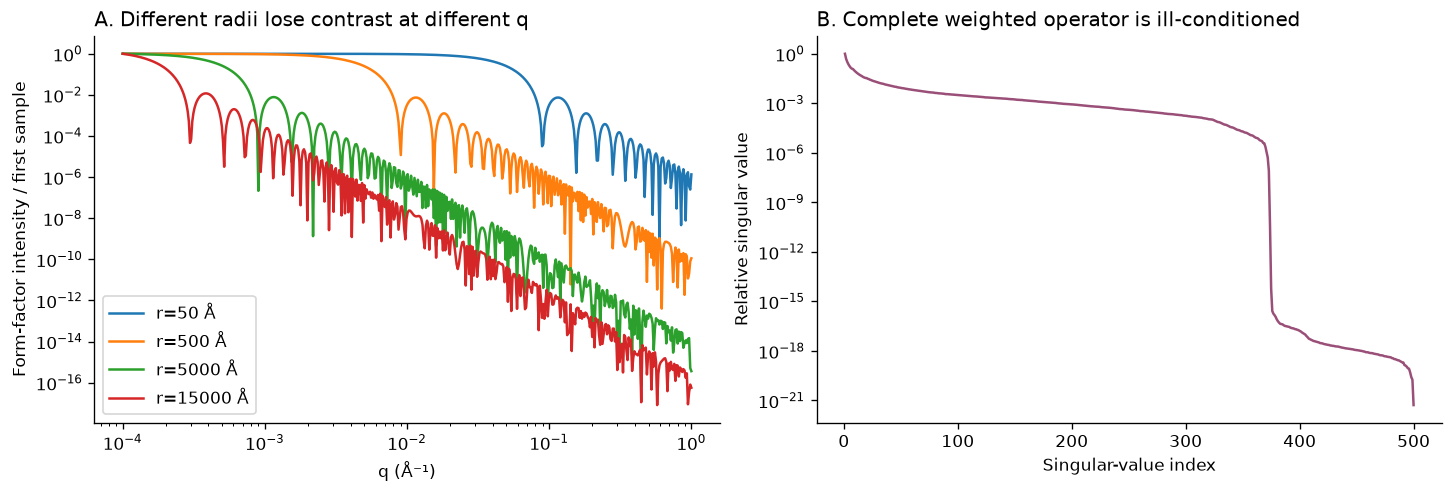

In [3]:
r=radius_grid();w=bin_widths(r);K=build_kernel(q,r)
singular=np.linalg.svd(K/error[:,None],compute_uv=False)
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for radius in [50.,500.,5000.,15000.]:
    line=build_kernel(q,np.array([radius]))[:,0];ax[0].loglog(q,line/line[0],label=f'r={radius:g} Å')
ax[0].set(xlabel='q (Å⁻¹)',ylabel='Form-factor intensity / first sample',title='A. Different radii lose contrast at different q');ax[0].legend()
ax[1].semilogy(np.arange(1,len(singular)+1),singular/singular[0],color='#9a4f78');ax[1].set(xlabel='Singular-value index',ylabel='Relative singular value',title='B. Complete weighted operator is ill-conditioned');plt.show()

## 3. Fresh complete recovery and independent source comparison

The next cell actively computes the full500-observation,500-radius reconstruction. The original source fixtures were captured before the local method was extracted. No cached result supplies a fresh plotted curve. Both required physical outputs are checked, and full observation residuals are retained.

Fresh full runtime(s) 0.03186180000193417 actual updates 101 background(cm^-1) 0.010006109388777107
{
  "ncc": 0.9999999999999999,
  "nrmse": 0.0,
  "background_abs_error": 0.0,
  "observation_reduced_chi_squared": 0.998884371764718
}
Integral conventions {'bin_sum_contrast': 0.9941012106797906, 'bin_weighted_rms_radius': 4509.783504723572, 'source_trapezoid_contrast': 0.9941011920804209}


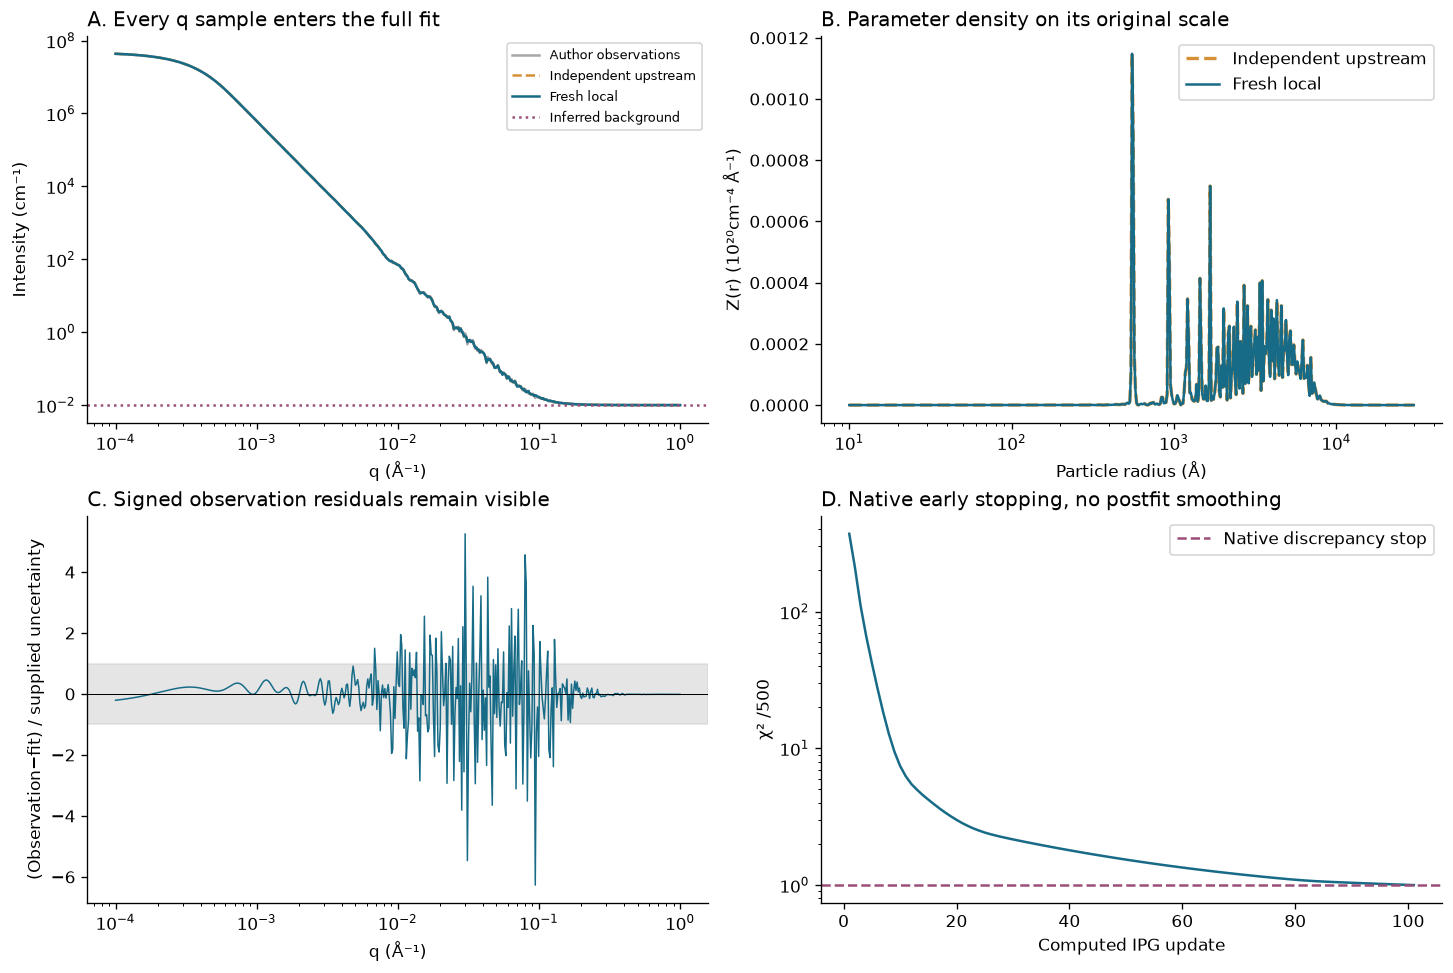

In [4]:
start=time.perf_counter();fresh=run();seconds=time.perf_counter()-start
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_standard.npz',reconstruction=fresh['reconstruction'][None],background=np.array([[fresh['background']]]))
metrics=density_metrics(fresh['reconstruction'],up['reconstruction'][0])
metrics.update(background_abs_error=abs(fresh['background']-float(up['background'][0,0])),observation_reduced_chi_squared=float(np.mean(fresh['residual']**2)))
print('Fresh full runtime(s)',seconds,'actual updates',fresh['iterations'],'background(cm^-1)',fresh['background'])
print(json.dumps(metrics,indent=2));print('Integral conventions',size_integrals(fresh['reconstruction'],r,w))
up_model=forward(up['reconstruction'][0],float(up['background'][0,0]),q,r,w)
fig,ax=plt.subplots(2,2,figsize=(12,8),layout='constrained')
ax[0,0].loglog(q,I,color='.65',label='Author observations');ax[0,0].loglog(q,up_model,'--',color='#d69036',label='Independent upstream');ax[0,0].loglog(q,fresh['model'],color='#176b87',label='Fresh local');ax[0,0].axhline(fresh['background'],ls=':',color='#9a4f78',label='Inferred background')
ax[0,0].set(xlabel='q (Å⁻¹)',ylabel='Intensity (cm⁻¹)',title='A. Every q sample enters the full fit');ax[0,0].legend(fontsize=8)
ax[0,1].semilogx(r,up['reconstruction'][0],'--',lw=2,color='#d69036',label='Independent upstream');ax[0,1].semilogx(r,fresh['reconstruction'],color='#176b87',label='Fresh local');ax[0,1].set(xlabel='Particle radius (Å)',ylabel='Z(r) (10²⁰cm⁻⁴ Å⁻¹)',title='B. Parameter density on its original scale');ax[0,1].legend()
ax[1,0].semilogx(q,fresh['residual'],color='#176b87',lw=.9);ax[1,0].axhspan(-1,1,color='.8',alpha=.5);ax[1,0].axhline(0,color='k',lw=.6);ax[1,0].set(xlabel='q (Å⁻¹)',ylabel='(Observation−fit) / supplied uncertainty',title='C. Signed observation residuals remain visible')
ax[1,1].semilogy(np.arange(1,len(fresh['history'])+1),fresh['history']/len(q),color='#176b87');ax[1,1].axhline(1,color='#9a4f78',ls='--',label='Native discrepancy stop');ax[1,1].set(xlabel='Computed IPG update',ylabel='χ² /500',title='D. Native early stopping, no postfit smoothing');ax[1,1].legend();plt.show()

## 4. Discretization is part of the inverse

The coarse200-bin source preflight failed to reach discrepancy even after20,000 iterations; those negative results remain in the private archive. Here each resolution is freshly fitted to **all500 observations**, with identical uncertainties and radius endpoints. Fine grids can resolve the rapidly varying kernel without implying unique microscopic features. The fixed500-bin output contract is unchanged.

200 updates 1000 χ²/N 2.9777182475550172 seconds 0.06287090003024787
500 updates 101 χ²/N 0.998884371764718 seconds 0.03091639996273443
1000 updates 62 χ²/N 0.9894923991456779 seconds 0.058836899988818914


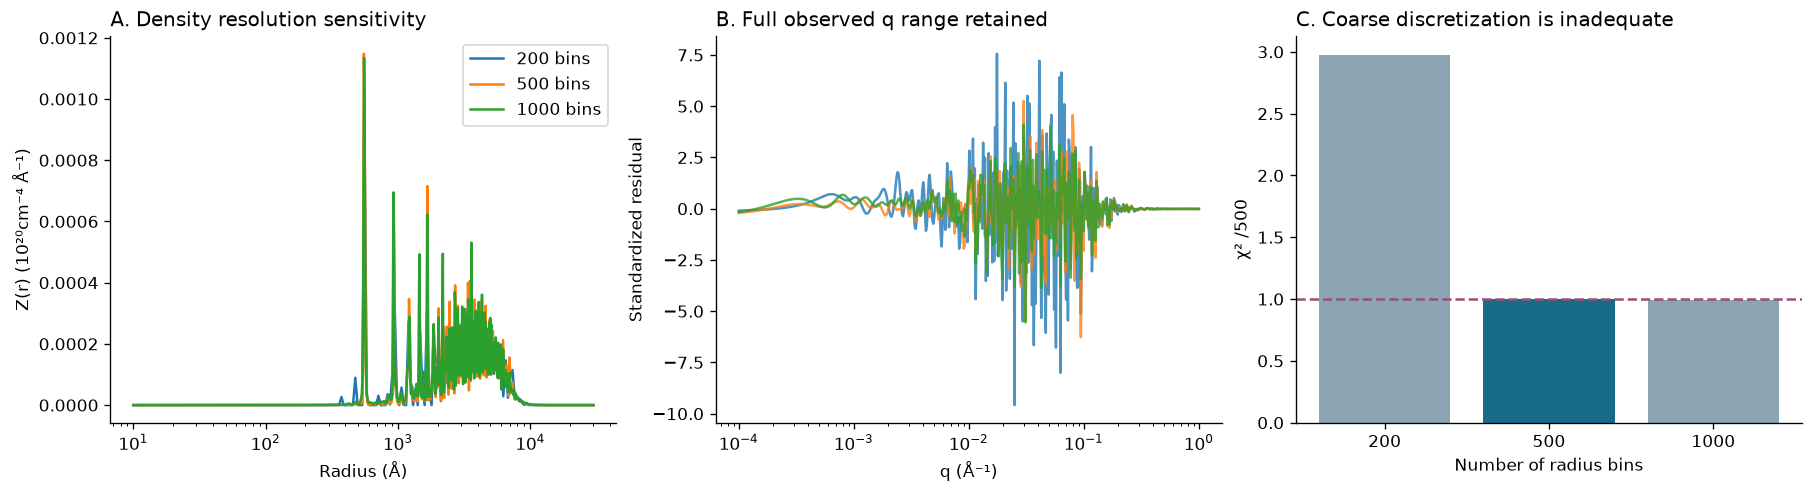

In [5]:
resolution=[]
for bins in [200,500,1000]:
    start=time.perf_counter();fit=reconstruct(q,I,error,n_bins=bins,max_iter=1000);elapsed=time.perf_counter()-start
    resolution.append((bins,fit,elapsed));print(bins,'updates',fit['iterations'],'χ²/N',np.mean(fit['residual']**2),'seconds',elapsed)
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
for bins,fit,elapsed in resolution:
    ax[0].semilogx(fit['radius'],fit['reconstruction'],label=f'{bins} bins')
    ax[1].semilogx(q,fit['residual'],label=f'{bins} bins',alpha=.8)
    ax[2].bar(str(bins),np.mean(fit['residual']**2),color='#176b87' if bins==500 else '#8ca5b3')
ax[0].set(xlabel='Radius (Å)',ylabel='Z(r) (10²⁰cm⁻⁴ Å⁻¹)',title='A. Density resolution sensitivity');ax[0].legend()
ax[1].set(xlabel='q (Å⁻¹)',ylabel='Standardized residual',title='B. Full observed q range retained')
ax[2].axhline(1,ls='--',color='#9a4f78');ax[2].set(xlabel='Number of radius bins',ylabel='χ² /500',title='C. Coarse discretization is inadequate');plt.show()

## 5. Background and finite uncertainty affect the density

The background is recomputed from input, not supplied as a true calibration. The first comparison deliberately perturbs this nuisance estimate and shows both its high-q consequences and the inferred density. The next ten fits follow the author's uncertainty procedure: add Gaussian perturbations with the supplied per-observation standard deviations, refit the complete acquisition and summarize the resulting spread. These are **sensitivity bands**, not independently validated confidence intervals or errors against known truth. Occasional below-zero perturbed intensities are retained in these mathematical sensitivity experiments; no new benchmark observations are generated or substituted.

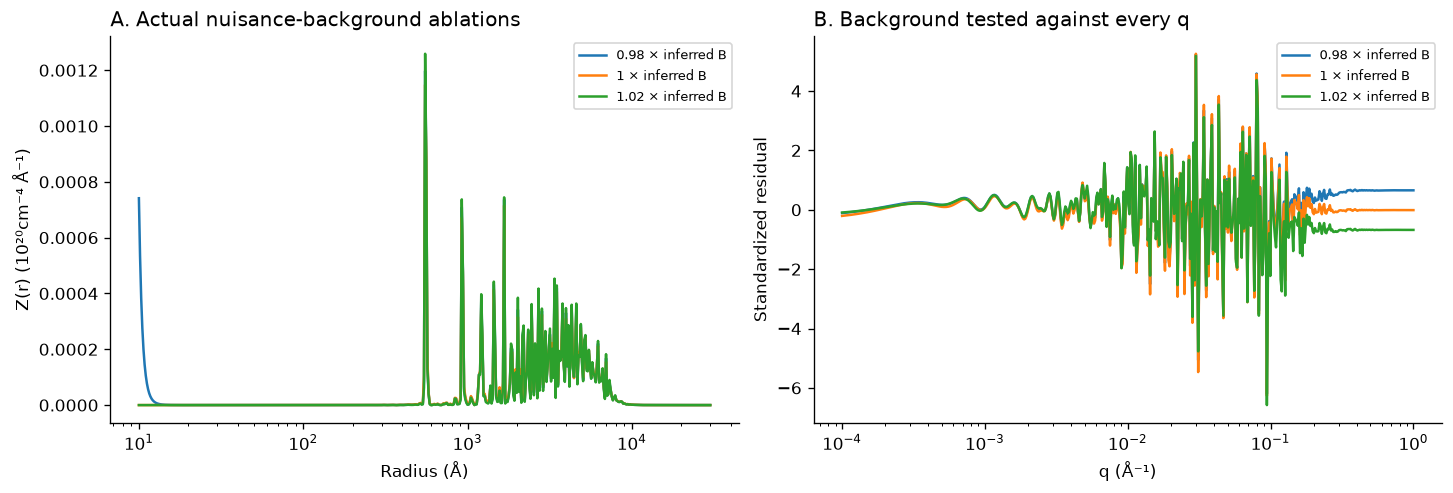

[
  {
    "run": 0,
    "seconds": 0.354476300009992,
    "iterations": 1000,
    "background": 0.009983400799392202,
    "perturbed_observation_chi_squared": 1.485268953172881,
    "original_observation_chi_squared": 0.9096436384234543
  },
  {
    "run": 1,
    "seconds": 0.35973669996019453,
    "iterations": 1000,
    "background": 0.010161341462449638,
    "perturbed_observation_chi_squared": 1.6269905207057271,
    "original_observation_chi_squared": 0.9877187953995573
  },
  {
    "run": 2,
    "seconds": 0.3515021000057459,
    "iterations": 1000,
    "background": 0.009999435643517015,
    "perturbed_observation_chi_squared": 1.6680494738014842,
    "original_observation_chi_squared": 0.8604280262111474
  },
  {
    "run": 3,
    "seconds": 0.3424005000269972,
    "iterations": 1000,
    "background": 0.01004013966649692,
    "perturbed_observation_chi_squared": 1.546930848392997,
    "original_observation_chi_squared": 0.9096585866974618
  },
  {
    "run": 4,
    "seconds": 

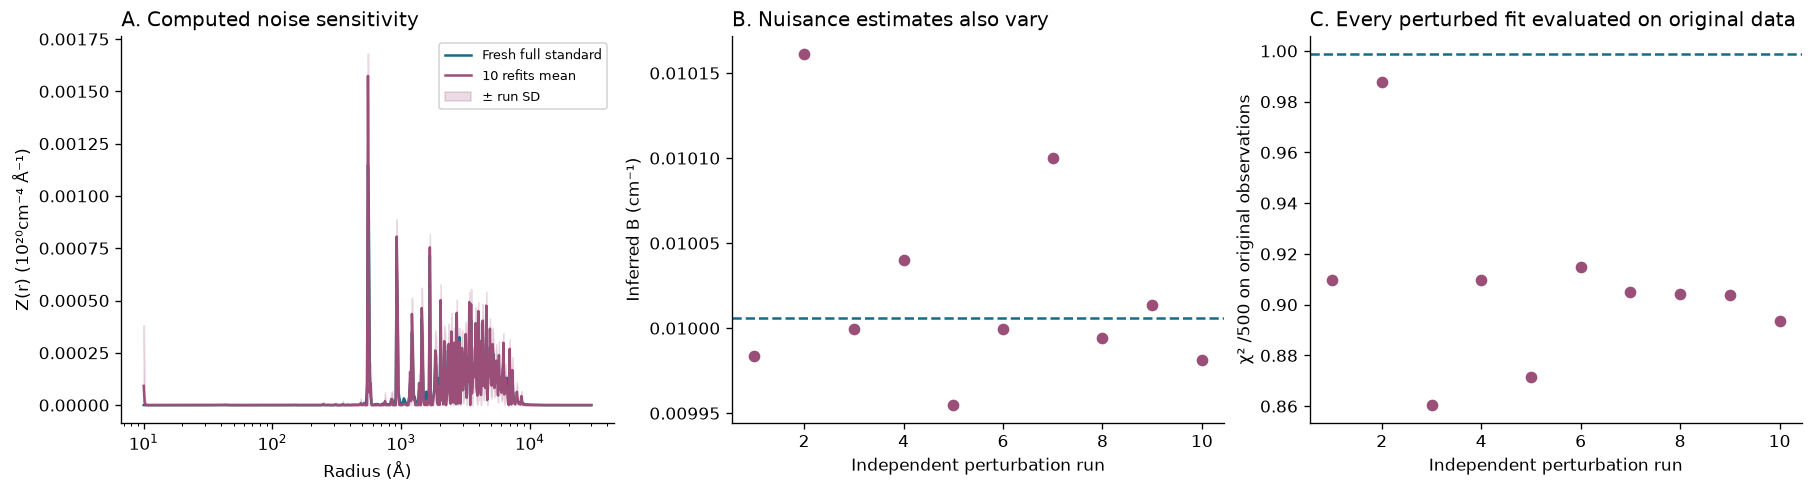

In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
background_runs=[]
for factor in [.98,1.,1.02]:
    fit=reconstruct(q,I,error,background=factor*fresh['background']);background_runs.append(fit)
    ax[0].semilogx(r,fit['reconstruction'],label=f'{factor:g} × inferred B');ax[1].semilogx(q,fit['residual'],label=f'{factor:g} × inferred B')
ax[0].set(xlabel='Radius (Å)',ylabel='Z(r) (10²⁰cm⁻⁴ Å⁻¹)',title='A. Actual nuisance-background ablations');ax[0].legend(fontsize=8)
ax[1].set(xlabel='q (Å⁻¹)',ylabel='Standardized residual',title='B. Background tested against every q');ax[1].legend(fontsize=8);plt.show()
rng=np.random.default_rng(20261026);perturbations=[];noise_records=[]
for j in range(10):
    changed=I+rng.normal(size=I.shape)*error;start=time.perf_counter();fit=reconstruct(q,changed,error);elapsed=time.perf_counter()-start
    perturbations.append(fit['reconstruction']);noise_records.append(dict(run=j,seconds=elapsed,iterations=fit['iterations'],background=fit['background'],perturbed_observation_chi_squared=float(np.mean(fit['residual']**2)),original_observation_chi_squared=float(np.mean(((fit['model']-I)/error)**2))))
perturbations=np.asarray(perturbations);mean=perturbations.mean(0);sd=perturbations.std(0,ddof=1)
print(json.dumps(noise_records,indent=2))
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
ax[0].semilogx(r,fresh['reconstruction'],color='#176b87',label='Fresh full standard');ax[0].semilogx(r,mean,color='#9a4f78',label='10 refits mean');ax[0].fill_between(r,np.maximum(mean-sd,0),mean+sd,color='#9a4f78',alpha=.2,label='± run SD');ax[0].set(xlabel='Radius (Å)',ylabel='Z(r) (10²⁰cm⁻⁴ Å⁻¹)',title='A. Computed noise sensitivity');ax[0].legend(fontsize=8)
ax[1].plot([a['run']+1 for a in noise_records],[a['background'] for a in noise_records],'o',color='#9a4f78');ax[1].axhline(fresh['background'],color='#176b87',ls='--');ax[1].set(xlabel='Independent perturbation run',ylabel='Inferred B (cm⁻¹)',title='B. Nuisance estimates also vary')
ax[2].plot([a['run']+1 for a in noise_records],[a['original_observation_chi_squared'] for a in noise_records],'o',color='#9a4f78');ax[2].axhline(np.mean(fresh['residual']**2),color='#176b87',ls='--');ax[2].set(xlabel='Independent perturbation run',ylabel='χ² /500 on original observations',title='C. Every perturbed fit evaluated on original data');plt.show()

## 6. Independent evaluation and scientific conclusion

The complete fresh method reproduces the independently executed author inverse and reaches its discrepancy criterion without dropping high-q observations or inflating uncertainties. The200-bin failure demonstrates why discretization qualification is mandatory. The background/noise comparisons preserve uncertainty in fine density features. Unit contrast recovers Z only; no absolute volume fraction, true radius distribution, experimental origin or microscopic uniqueness is claimed. The source trapezoid diagnostic and actual discrete bin-mass sum are explicitly different at endpoints. The source's radius moment is described as RMS radius rather than incorrectly calling it particle radius of gyration.

In [7]:
import importlib.util
spec=importlib.util.spec_from_file_location('sizes_review_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert exit_code==0
assert len(q)==500 and len(fresh['reconstruction'])==500
print('Review completed: independent source comparison, fresh full solve, three resolutions, three backgrounds and ten perturbation fits.')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "density_ncc": 0.9999999999999999,
    "density_nrmse": 0.0,
    "background_abs_error": 0.0,
    "observation_reduced_chi_squared": 0.9988843717647178
  },
  "thresholds": {
    "density_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "density_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "background_abs_error": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "observation_reduced_chi_squared": {
      "comparison": "<=",
      "boundary": 1.01
    }
  },
  "errors": []
}
Review completed: independent source comparison, fresh full solve, three resolutions, three backgrounds and ten perturbation fits.
